In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.metrics import (
    make_scorer, accuracy_score, precision_score, recall_score, 
    f1_score, classification_report, confusion_matrix, 
    ConfusionMatrixDisplay, multilabel_confusion_matrix
)
from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.multioutput import MultiOutputClassifier

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from scipy.stats import randint, uniform, loguniform

import time
import warnings
warnings.filterwarnings("ignore")

In [2]:
# TODO: Track train, test, and tuning time

# Set seed for reproducibility
seed = 67

# Show all dataframe columns
pd.set_option("display.max_columns", None)

# Seaborn plot colors
sns.set_palette("viridis")

# Phase columns
phase_cols = ['BCC', 'FCC', 'IM', 'AM']
phase_combs = ['BCC', 'FCC', 'BCC+FCC', 'AM', 'IM', 'FCC+IM', 'FCC+AM',
               'BCC+IM', 'BCC+AM', 'BCC+FCC+IM', 'BCC+FCC+AM']
has_phase_cols = ['has_BCC', 'has_FCC', 'has_IM', 'has_AM']

# Setup

In [3]:
X_train      = pd.read_csv("data/X_train.csv", index_col=0)
X_test       = pd.read_csv("data/X_test.csv", index_col=0)
y_mulb_train = pd.read_csv("data/y_mulb_train.csv", index_col=0)
y_mulb_test  = pd.read_csv("data/y_mulb_test.csv", index_col=0)

In [4]:
# Turns y_mulb --> y_base --> SMOTE --> back to y_mulb
class MultilabelSMOTE(BaseEstimator):
    def __init__(self, smote, phase_order=phase_cols):
        self.smote = smote
        self.phase_order = phase_order

    def _bits_to_phase_str(self, bits):
        return '+'.join(p for p, b in zip(self.phase_order, bits) if b)

    def _phase_str_to_bits(self, phase_str):
        present = set(phase_str.split('+'))
        return [1 if p in present else 0 for p in self.phase_order]

    def fit_resample(self, X, y):
        y_arr = np.asarray(y)
        phase_strs = pd.Series(
            [self._bits_to_phase_str(row) for row in y_arr],
            index=getattr(y, "index", None),
        )

        X_res, phase_strs_res = self.smote.fit_resample(X, phase_strs)

        y_res = np.array([self._phase_str_to_bits(p) for p in phase_strs_res])
        return X_res, pd.DataFrame(y_res, columns=has_phase_cols)

In [5]:
# Save results
results = []

# Double points of minority classes, keep majority untouched
# Preserves relative gaps and increases minority representation
minority_double_strategy = {
    'IM': 898,
    'FCC+IM': 278,
    'FCC+AM': 230,
    'BCC+IM': 180,
    'BCC+AM': 114,
    'BCC+FCC+IM': 62,
    'BCC+FCC+AM': 50,
}

smote = SMOTE(sampling_strategy=minority_double_strategy, random_state=seed)

# Create scale -> SMOTE -> train pipeline
def create_pipe(clf):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('smote', MultilabelSMOTE(smote=smote)),
        ('clf', clf),
    ])

In [6]:
# Setup metric lookups

_METRIC_DEFS = {
    "accuracy":           (accuracy_score,  {}),
    "precision_macro":    (precision_score, {"average": "macro",    "zero_division": 0}),
    "recall_macro":       (recall_score,    {"average": "macro",    "zero_division": 0}),
    "f1_macro":           (f1_score,        {"average": "macro",    "zero_division": 0}),
    "precision_weighted": (precision_score, {"average": "weighted", "zero_division": 0}),
    "recall_weighted":    (recall_score,    {"average": "weighted", "zero_division": 0}),
    "f1_weighted":        (f1_score,        {"average": "weighted", "zero_division": 0}),
}

SCORING = {name: make_scorer(f, **kw) for name, (f, kw) in _METRIC_DEFS.items()}

def _metrics(y_true, y_pred):
    return {name: f(y_true, y_pred, **kw) for name, (f, kw) in _METRIC_DEFS.items()}

In [7]:
def evaluate_model(model, X_train, y_train, X_test, y_test, name="model"):
    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)

    trm = _metrics(y_train, y_train_pred)
    tem = _metrics(y_test,  y_test_pred)

    print(name)
    print(f"{'Metrics':<18} | {'Train':<6} | {'Test'}")
    print("-" * 37)
    for m in trm:
        print(f"{m:<18} | {trm[m]:<6.4f} | {tem[m]:.4f}")
    print("")

    print(classification_report(y_test, y_test_pred, digits=4, zero_division=0,
                                 target_names=has_phase_cols))

    cms = multilabel_confusion_matrix(y_test, y_test_pred)
    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    for ax, cm, label in zip(axes, cms, has_phase_cols):
        ConfusionMatrixDisplay(cm, display_labels=["Absent", "Present"]).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(label)
    fig.suptitle(f"Per-phase Confusion Matrices - {name}")
    plt.tight_layout()
    plt.show()
    cm = cms

    return {
        "name": name, "train": trm, "test": tem, "cm": cm,
        "y_train_pred": y_train_pred, "y_test_pred": y_test_pred,
    }

In [8]:
def tune_model(pipe, param_distributions, X, y, *,
               n_iter=100, val_size=0.2, random_state=seed,
               scoring=SCORING["f1_macro"], name="model", n_jobs=-1, verbose=1):

    idx = np.arange(len(y))
    tr_idx, val_idx = train_test_split(idx, test_size=val_size, stratify=y, random_state=random_state)
    cv_single_split = [(tr_idx, val_idx)]

    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_distributions,
        n_iter=n_iter,
        scoring=scoring,
        cv=cv_single_split,
        refit=True,
        random_state=random_state,
        n_jobs=n_jobs,
        verbose=verbose,
    )
    search.fit(X, y)

    print(f"\n=== RandomizedSearchCV ({name}) ===")
    print(f"Best score: {search.best_score_:.4f}")
    for k, v in search.best_params_.items():
        print(f"  {k}: {v}")
    print("")

    return search

In [9]:
def run_model(name, estimator, param_dist, X_train, y_train, X_test, y_test, results, n_iter=100):
    default_pipe = create_pipe(clone(estimator))
    default_pipe.fit(X_train, y_train)
    results.append(
        evaluate_model(
            default_pipe, X_train, y_train, X_test, y_test, name=f"{name}_def"
        )
    )

    search = tune_model(create_pipe(clone(estimator)), param_dist, X_train, y_train, name=name, n_iter=n_iter)
    tuned = search.best_estimator_
    results.append(
        evaluate_model(
            tuned, X_train, y_train, X_test, y_test, name=f"{name}_tun"
        )
    )

    return results

In [10]:
def summarize_models(results):
    rows = []
    metric_order = list(_METRIC_DEFS.keys())
    for r in results:
        row = {"Model": r["name"]}
        for m in metric_order:
            row[m] = r["test"][m]
        rows.append(row)

    return pd.DataFrame(rows).set_index("Model")[metric_order]

# k-Nearest Neighbors

kNN_mulb_def
Metrics            | Train  | Test
-------------------------------------
accuracy           | 0.8778 | 0.8401
precision_macro    | 0.8982 | 0.8769
recall_macro       | 0.9476 | 0.9111
f1_macro           | 0.9215 | 0.8927
precision_weighted | 0.9215 | 0.9043
recall_weighted    | 0.9509 | 0.9250
f1_weighted        | 0.9355 | 0.9141

              precision    recall  f1-score   support

     has_BCC     0.9214    0.9149    0.9181       282
     has_FCC     0.9193    0.9527    0.9357       275
      has_IM     0.7108    0.8310    0.7662        71
      has_AM     0.9560    0.9457    0.9508        92

   micro avg     0.9012    0.9250    0.9130       720
   macro avg     0.8769    0.9111    0.8927       720
weighted avg     0.9043    0.9250    0.9141       720
 samples avg     0.9100    0.9269    0.9101       720



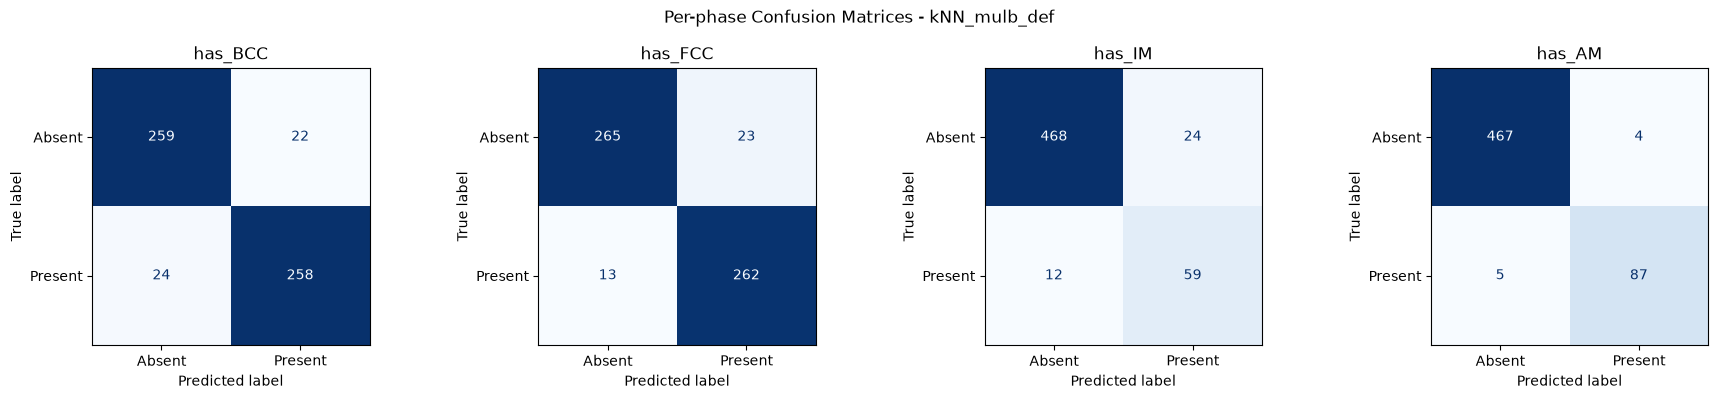

Fitting 1 folds for each of 100 candidates, totalling 100 fits

=== RandomizedSearchCV (kNN_mulb) ===
Best score: 0.8833
  clf__metric: minkowski
  clf__n_neighbors: 6
  clf__p: 2
  clf__weights: distance

kNN_mulb_tun
Metrics            | Train  | Test
-------------------------------------
accuracy           | 0.9949 | 0.8153
precision_macro    | 1.0000 | 0.8715
recall_macro       | 0.9950 | 0.8722
f1_macro           | 0.9975 | 0.8718
precision_weighted | 1.0000 | 0.8977
recall_weighted    | 0.9951 | 0.8986
f1_weighted        | 0.9975 | 0.8981

              precision    recall  f1-score   support

     has_BCC     0.9004    0.8972    0.8988       282
     has_FCC     0.9242    0.9309    0.9275       275
      has_IM     0.6944    0.7042    0.6993        71
      has_AM     0.9670    0.9565    0.9617        92

   micro avg     0.8974    0.8986    0.8980       720
   macro avg     0.8715    0.8722    0.8718       720
weighted avg     0.8977    0.8986    0.8981       720
 samples avg  

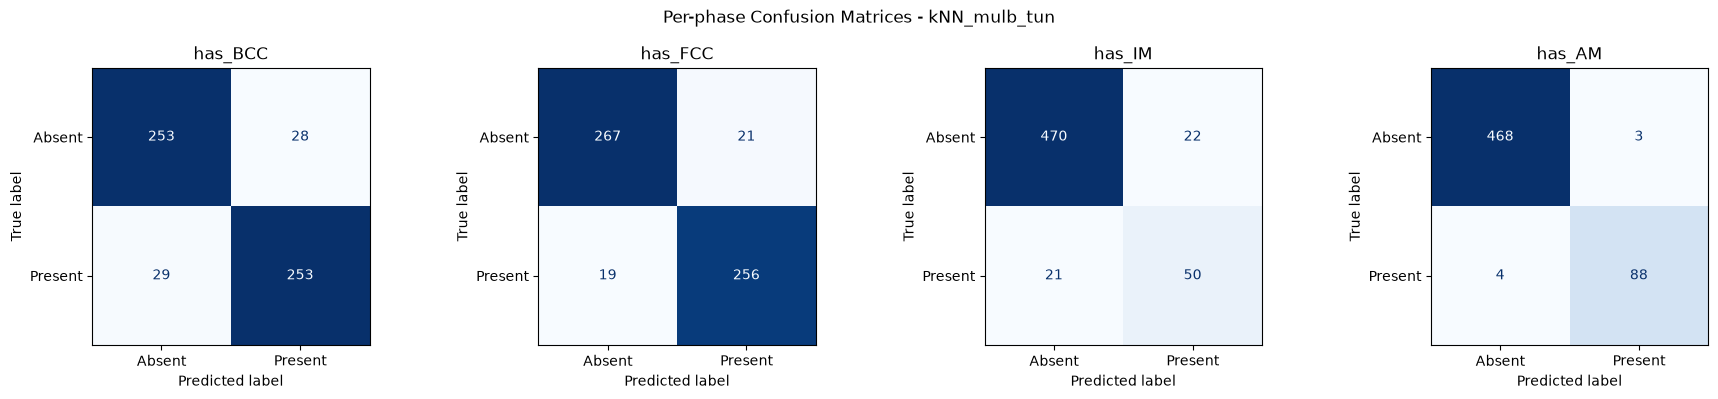

In [11]:
knn_params = {
    "clf__n_neighbors": randint(3, 16),
    "clf__weights":     ["uniform", "distance"],
    "clf__p":           [1, 2],
    "clf__metric":      ["euclidean", "manhattan", "minkowski"],
}

results = run_model(
    'kNN_mulb', KNeighborsClassifier(), knn_params,
    X_train, y_mulb_train, X_test, y_mulb_test, results,
)

# Multilayer Perceptron

MLP_mulb_def
Metrics            | Train  | Test
-------------------------------------
accuracy           | 0.7450 | 0.7478
precision_macro    | 0.8439 | 0.8556
recall_macro       | 0.8495 | 0.8401
f1_macro           | 0.8457 | 0.8455
precision_weighted | 0.8725 | 0.8861
recall_weighted    | 0.8670 | 0.8569
f1_weighted        | 0.8691 | 0.8701

              precision    recall  f1-score   support

     has_BCC     0.9080    0.8404    0.8729       282
     has_FCC     0.9018    0.9018    0.9018       275
      has_IM     0.6867    0.8028    0.7403        71
      has_AM     0.9259    0.8152    0.8671        92

   micro avg     0.8814    0.8569    0.8690       720
   macro avg     0.8556    0.8401    0.8455       720
weighted avg     0.8861    0.8569    0.8701       720
 samples avg     0.8896    0.8777    0.8686       720



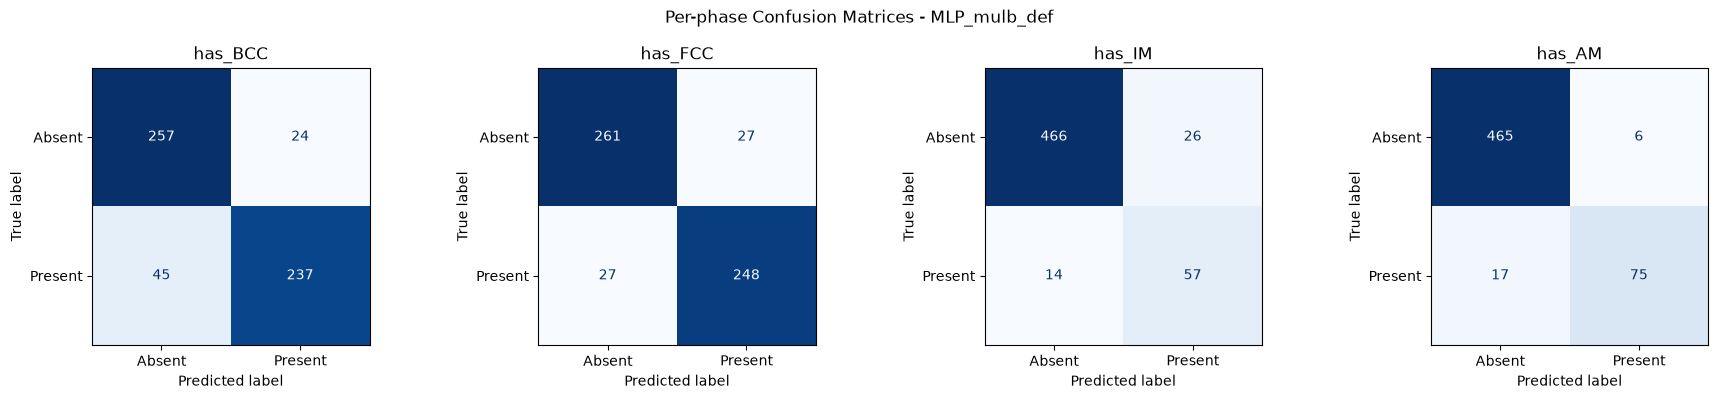

Fitting 1 folds for each of 100 candidates, totalling 100 fits

=== RandomizedSearchCV (MLP_mulb) ===
Best score: 0.8881
  clf__activation: relu
  clf__alpha: 0.0037284511350642235
  clf__batch_size: 32
  clf__hidden_layer_sizes: (128, 64)
  clf__learning_rate_init: 0.001268337149859175
  clf__max_iter: 500
  clf__solver: adam

MLP_mulb_tun
Metrics            | Train  | Test
-------------------------------------
accuracy           | 0.8541 | 0.8313
precision_macro    | 0.8966 | 0.8892
recall_macro       | 0.9203 | 0.9003
f1_macro           | 0.9074 | 0.8938
precision_weighted | 0.9148 | 0.9076
recall_weighted    | 0.9334 | 0.9167
f1_weighted        | 0.9234 | 0.9116

              precision    recall  f1-score   support

     has_BCC     0.9170    0.9007    0.9088       282
     has_FCC     0.9164    0.9564    0.9359       275
      has_IM     0.7468    0.8310    0.7867        71
      has_AM     0.9767    0.9130    0.9438        92

   micro avg     0.9053    0.9167    0.9110       72

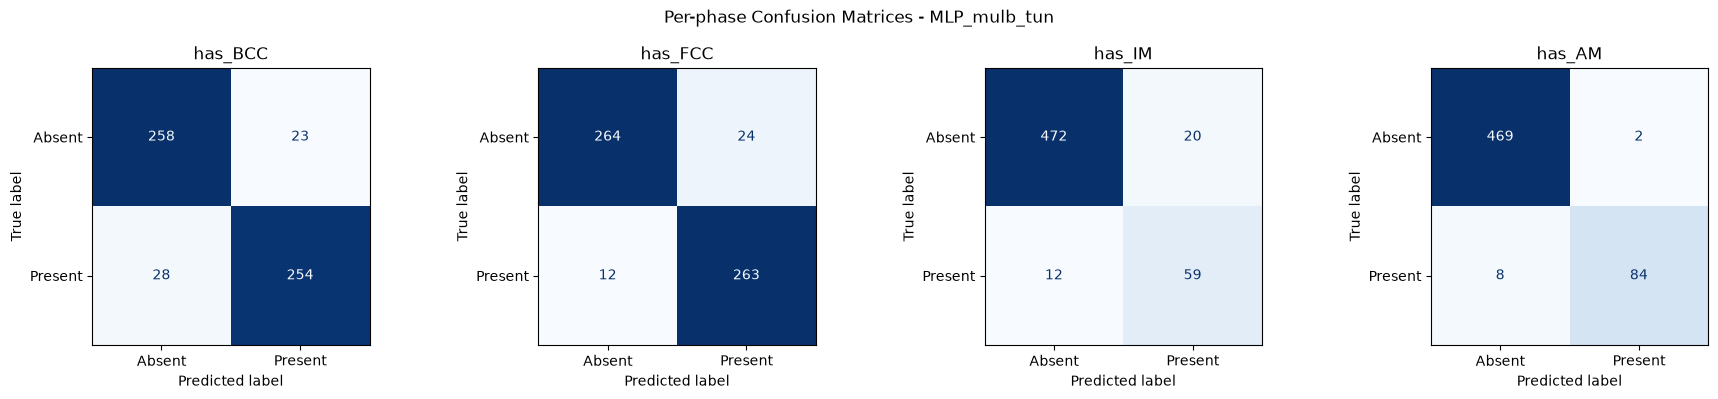

In [12]:
mlp_params = {
    "clf__hidden_layer_sizes": [(64,), (128,), (64, 32), (128, 64), (128, 64, 32)],
    "clf__activation":         ["relu", "tanh"],
    "clf__solver":             ["adam", "sgd"],
    "clf__alpha":              loguniform(1e-5, 1e-1),
    "clf__learning_rate_init": loguniform(1e-4, 1e-2),
    "clf__batch_size":         [32, 64, 128],
    "clf__max_iter":           [500],
}

results = run_model(
    "MLP_mulb", MLPClassifier(random_state=seed, early_stopping=True), mlp_params,
    X_train, y_mulb_train, X_test, y_mulb_test, results,
)

# Support Vector Classifier

SVC_mulb_def
Metrics            | Train  | Test
-------------------------------------
accuracy           | 0.7456 | 0.7389
precision_macro    | 0.8461 | 0.8516
recall_macro       | 0.8424 | 0.8293
f1_macro           | 0.8439 | 0.8395
precision_weighted | 0.8725 | 0.8788
recall_weighted    | 0.8670 | 0.8569
f1_weighted        | 0.8694 | 0.8673

              precision    recall  f1-score   support

     has_BCC     0.8963    0.8582    0.8768       282
     has_FCC     0.8986    0.9018    0.9002       275
      has_IM     0.7333    0.7746    0.7534        71
      has_AM     0.8780    0.7826    0.8276        92

   micro avg     0.8777    0.8569    0.8672       720
   macro avg     0.8516    0.8293    0.8395       720
weighted avg     0.8788    0.8569    0.8673       720
 samples avg     0.8949    0.8801    0.8712       720



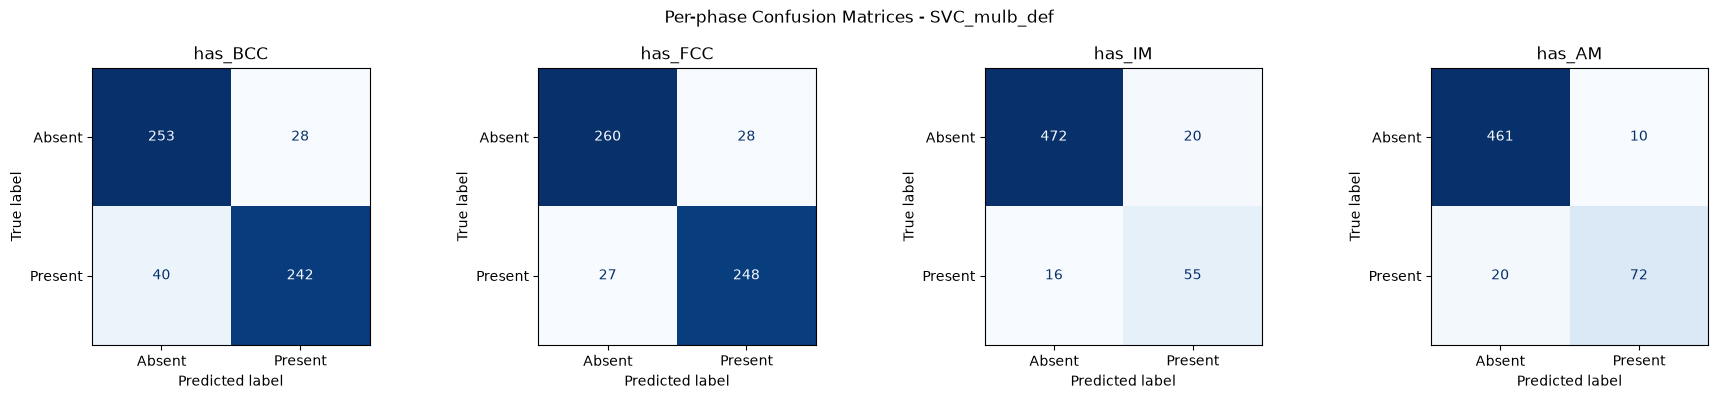

Fitting 1 folds for each of 100 candidates, totalling 100 fits

=== RandomizedSearchCV (SVC_mulb) ===
Best score: 0.8929
  clf__estimator__C: 72.39069698175814
  clf__estimator__coef0: 0.5231948861249859
  clf__estimator__degree: 3
  clf__estimator__gamma: 0.4454942561781333
  clf__estimator__kernel: rbf

SVC_mulb_tun
Metrics            | Train  | Test
-------------------------------------
accuracy           | 0.8753 | 0.8366
precision_macro    | 0.9069 | 0.8877
recall_macro       | 0.9410 | 0.9182
f1_macro           | 0.9231 | 0.9022
precision_weighted | 0.9265 | 0.9095
recall_weighted    | 0.9458 | 0.9292
f1_weighted        | 0.9356 | 0.9189

              precision    recall  f1-score   support

     has_BCC     0.9211    0.9113    0.9162       282
     has_FCC     0.9231    0.9600    0.9412       275
      has_IM     0.7500    0.8451    0.7947        71
      has_AM     0.9565    0.9565    0.9565        92

   micro avg     0.9077    0.9292    0.9183       720
   macro avg     0.88

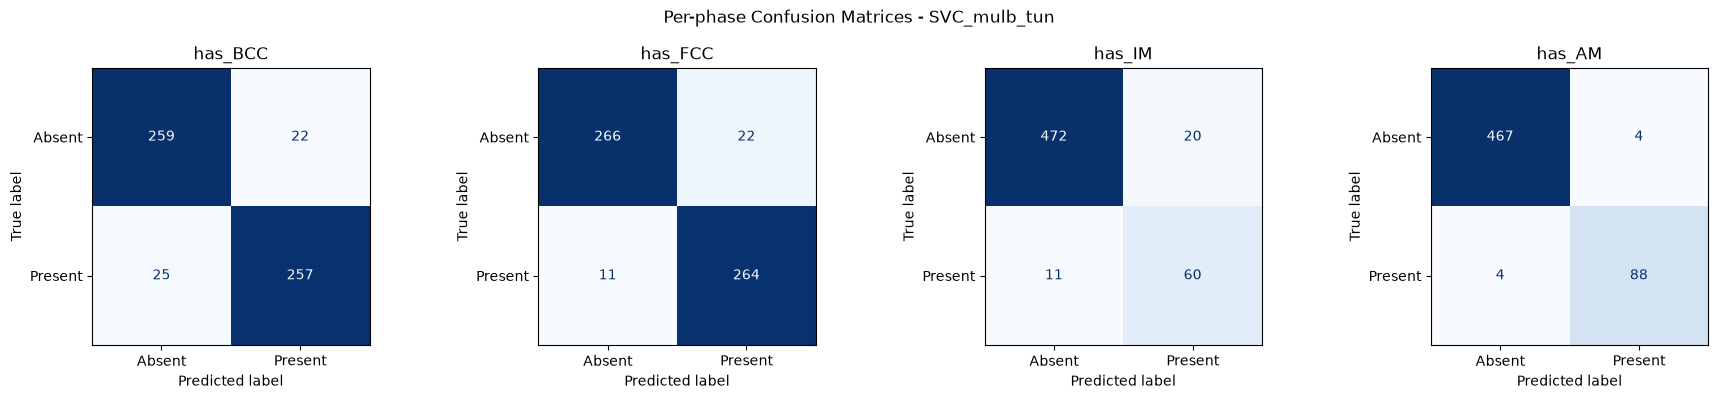

In [13]:
svc_params = {
    "clf__estimator__C":      loguniform(1e-2, 1e3),
    "clf__estimator__kernel": ["rbf", "poly", "sigmoid"],
    "clf__estimator__gamma":  loguniform(1e-4, 1e0),
    "clf__estimator__degree": randint(2, 5),
    "clf__estimator__coef0":  uniform(0, 1),
}

results = run_model(
    "SVC_mulb", MultiOutputClassifier(SVC(probability=True, random_state=seed)), svc_params,
    X_train, y_mulb_train, X_test, y_mulb_test, results,
)

# Random Forest

RF_mulb_def
Metrics            | Train  | Test
-------------------------------------
accuracy           | 0.9921 | 0.8171
precision_macro    | 0.9958 | 0.8756
recall_macro       | 0.9949 | 0.8616
f1_macro           | 0.9953 | 0.8685
precision_weighted | 0.9949 | 0.8994
recall_weighted    | 0.9964 | 0.8944
f1_weighted        | 0.9957 | 0.8968

              precision    recall  f1-score   support

     has_BCC     0.8975    0.9007    0.8991       282
     has_FCC     0.9239    0.9273    0.9256       275
      has_IM     0.6812    0.6620    0.6714        71
      has_AM     1.0000    0.9565    0.9778        92

   micro avg     0.8994    0.8944    0.8969       720
   macro avg     0.8756    0.8616    0.8685       720
weighted avg     0.8994    0.8944    0.8968       720
 samples avg     0.9047    0.9002    0.8927       720



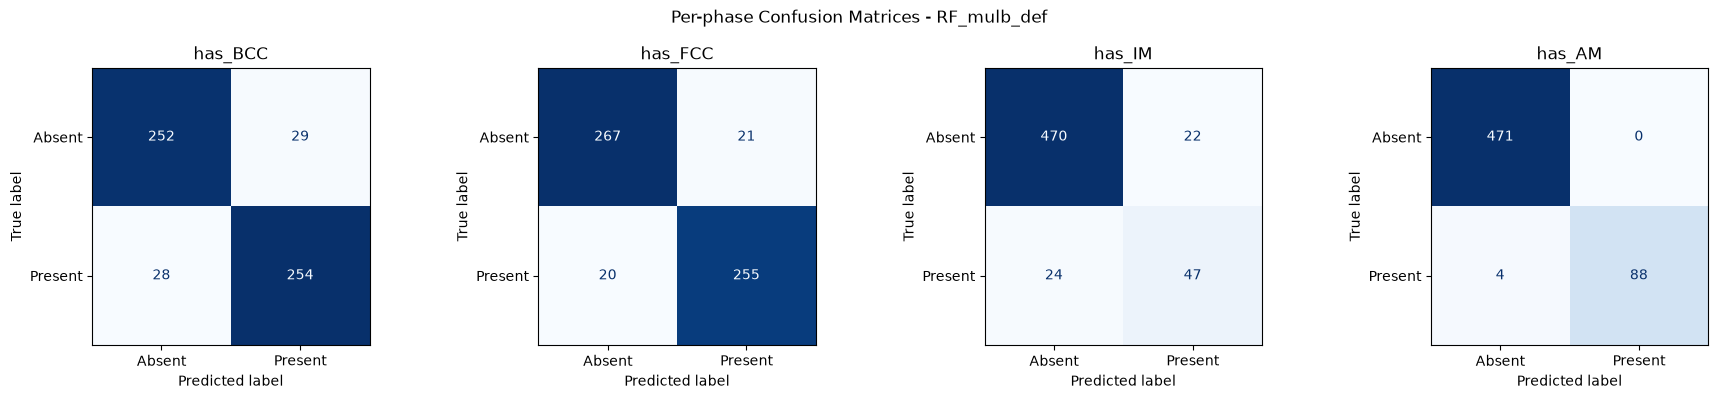

Fitting 1 folds for each of 100 candidates, totalling 100 fits

=== RandomizedSearchCV (RF_mulb) ===
Best score: 0.8954
  clf__bootstrap: False
  clf__class_weight: balanced
  clf__max_depth: 19
  clf__max_features: sqrt
  clf__min_samples_leaf: 4
  clf__min_samples_split: 7
  clf__n_estimators: 460

RF_mulb_tun
Metrics            | Train  | Test
-------------------------------------
accuracy           | 0.9296 | 0.8330
precision_macro    | 0.9288 | 0.8858
recall_macro       | 0.9808 | 0.9145
f1_macro           | 0.9520 | 0.8975
precision_weighted | 0.9532 | 0.9138
recall_weighted    | 0.9713 | 0.9153
f1_weighted        | 0.9609 | 0.9133

              precision    recall  f1-score   support

     has_BCC     0.9370    0.8972    0.9167       282
     has_FCC     0.9209    0.9309    0.9259       275
      has_IM     0.6966    0.8732    0.7750        71
      has_AM     0.9888    0.9565    0.9724        92

   micro avg     0.9077    0.9153    0.9115       720
   macro avg     0.8858    

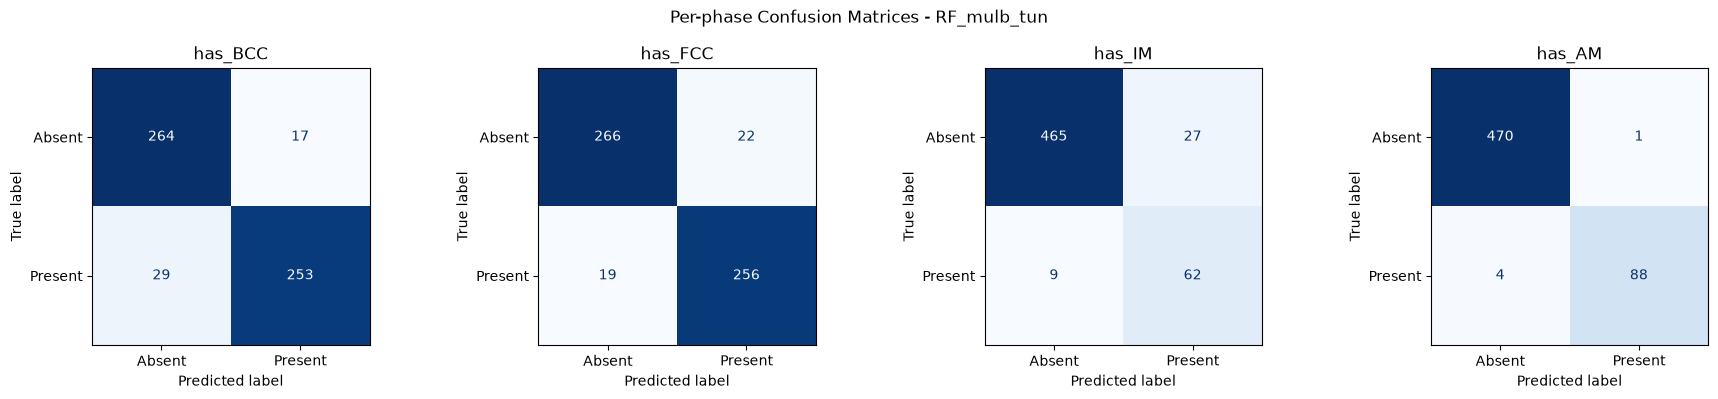

In [14]:
rf_params = {
    "clf__n_estimators":      randint(200, 1000),
    "clf__max_depth":         randint(3, 30),
    "clf__min_samples_split": randint(2, 20),
    "clf__min_samples_leaf":  randint(1, 10),
    "clf__max_features":      ["sqrt", "log2", None],
    "clf__bootstrap":         [True, False],
    "clf__class_weight":      [None, "balanced"],
}

results = run_model(
    "RF_mulb", RandomForestClassifier(random_state=seed, n_jobs=-1), rf_params,
    X_train, y_mulb_train, X_test, y_mulb_test, results,
)

# XGBoost

In [15]:
# Label encoded wrapper for XGBoost
class LabelEncodedXGB(BaseEstimator, ClassifierMixin):
    def __init__(self, **xgb_params):
        self.xgb_params = xgb_params

    def get_params(self, deep=True):
        return dict(self.xgb_params)

    def set_params(self, **params):
        self.xgb_params.update(params)
        return self

    def fit(self, X, y):
        self.le_ = LabelEncoder().fit(y)
        self.estimator_ = XGBClassifier(**self.xgb_params).fit(
            X, self.le_.transform(y)
        )
        self.classes_ = self.le_.classes_
        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        return self.le_.inverse_transform(
            self.estimator_.predict(X).astype(int)
        )

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)

    def decision_function(self, X):
        return self.estimator_.decision_function(X)

XGB_mulb_def
Metrics            | Train  | Test
-------------------------------------
accuracy           | 0.9379 | 0.8117
precision_macro    | 0.9525 | 0.8708
recall_macro       | 0.9759 | 0.8722
f1_macro           | 0.9638 | 0.8713
precision_weighted | 0.9600 | 0.8990
recall_weighted    | 0.9754 | 0.8986
f1_weighted        | 0.9675 | 0.8987

              precision    recall  f1-score   support

     has_BCC     0.9075    0.9043    0.9059       282
     has_FCC     0.9203    0.9236    0.9220       275
      has_IM     0.6667    0.7042    0.6849        71
      has_AM     0.9888    0.9565    0.9724        92

   micro avg     0.8974    0.8986    0.8980       720
   macro avg     0.8708    0.8722    0.8713       720
weighted avg     0.8990    0.8986    0.8987       720
 samples avg     0.9023    0.9050    0.8935       720



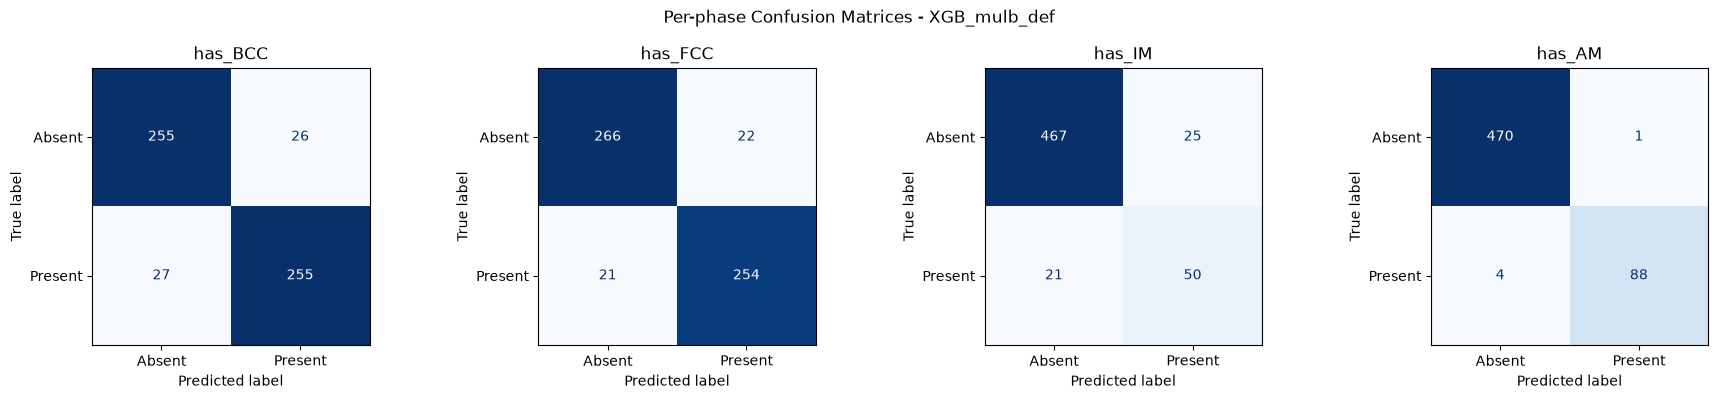

Fitting 1 folds for each of 100 candidates, totalling 100 fits

=== RandomizedSearchCV (XGB_mulb) ===
Best score: 0.9012
  clf__estimator__colsample_bytree: 0.9362218082427647
  clf__estimator__gamma: 0.010171697730576969
  clf__estimator__learning_rate: 0.02081351467991725
  clf__estimator__max_depth: 11
  clf__estimator__min_child_weight: 3
  clf__estimator__n_estimators: 286
  clf__estimator__reg_alpha: 0.017307617272234687
  clf__estimator__reg_lambda: 0.48212163577219275
  clf__estimator__subsample: 0.9179380899850627

XGB_mulb_tun
Metrics            | Train  | Test
-------------------------------------
accuracy           | 0.9148 | 0.8259
precision_macro    | 0.9321 | 0.8878
recall_macro       | 0.9645 | 0.8960
f1_macro           | 0.9473 | 0.8912
precision_weighted | 0.9461 | 0.9097
recall_weighted    | 0.9654 | 0.9069
f1_weighted        | 0.9552 | 0.9079

              precision    recall  f1-score   support

     has_BCC     0.9299    0.8936    0.9114       282
     has_FCC   

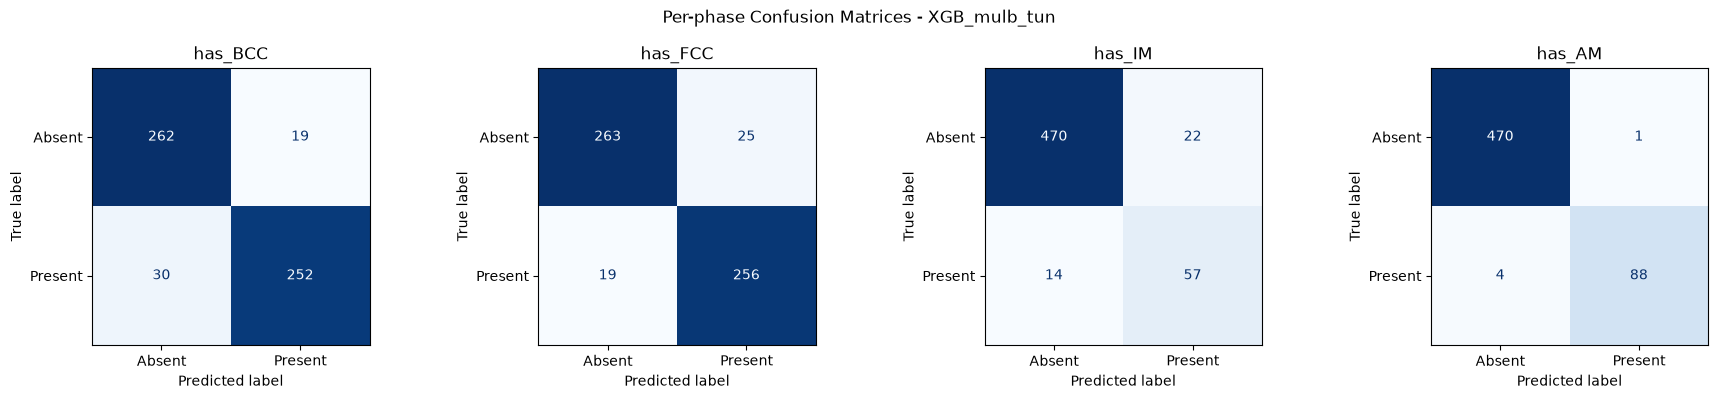

In [16]:
xgb_params = {
    "clf__estimator__n_estimators":     randint(200, 1000),
    "clf__estimator__max_depth":        randint(3, 12),
    "clf__estimator__learning_rate":    loguniform(1e-3, 3e-1),
    "clf__estimator__subsample":        uniform(0.5, 0.5),
    "clf__estimator__colsample_bytree": uniform(0.5, 0.5),
    "clf__estimator__min_child_weight": randint(1, 10),
    "clf__estimator__gamma":            loguniform(1e-3, 10),
    "clf__estimator__reg_alpha":        loguniform(1e-3, 10),
    "clf__estimator__reg_lambda":       loguniform(1e-3, 10),
}

results = run_model(
    "XGB_mulb", MultiOutputClassifier(LabelEncodedXGB(random_state=seed, tree_method="hist", eval_metric="logloss")), xgb_params,
    X_train, y_mulb_train, X_test, y_mulb_test, results,
)

# Summary

In [21]:
summary = summarize_models(results)
display(summary.round(4))

,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
Model,,,,,,,
kNN_mulb_def,0.8401,0.8769,0.9111,0.8927,0.9043,0.9250,0.9141
kNN_mulb_tun,0.8153,0.8715,0.8722,0.8718,0.8977,0.8986,0.8981
MLP_mulb_def,0.7478,0.8556,0.8401,0.8455,0.8861,0.8569,0.8701
MLP_mulb_tun,0.8313,0.8892,0.9003,0.8938,0.9076,0.9167,0.9116
SVC_mulb_def,0.7389,0.8516,0.8293,0.8395,0.8788,0.8569,0.8673
SVC_mulb_tun,0.8366,0.8877,0.9182,0.9022,0.9095,0.9292,0.9189
RF_mulb_def,0.8171,0.8756,0.8616,0.8685,0.8994,0.8944,0.8968
RF_mulb_tun,0.8330,0.8858,0.9145,0.8975,0.9138,0.9153,0.9133
XGB_mulb_def,0.8117,0.8708,0.8722,0.8713,0.8990,0.8986,0.8987


In [26]:
def results_to_csv(results, path="results.csv", labels=None):
    rows = []
    for r in results:
        row = {"name": r["name"]}

        for split in ("train", "test"):
            for metric, value in r[split].items():
                row[f"{split}_{metric}"] = value

        cm = np.asarray(r["cm"])            # (n_labels, 2, 2): [[tn, fp], [fn, tp]]
        cm_labels = labels if labels is not None else [f"label_{i}" for i in range(len(cm))]
        for label, m in zip(cm_labels, cm):
            (tn, fp), (fn, tp) = m
            row[f"cm_{label}_tn"] = int(tn)
            row[f"cm_{label}_fp"] = int(fp)
            row[f"cm_{label}_fn"] = int(fn)
            row[f"cm_{label}_tp"] = int(tp)

        rows.append(row)

    return pd.DataFrame(rows)

df = results_to_csv(results, "data/multilabel_results.csv", labels=has_phase_cols)
df.to_csv("data/multilabel_results.csv", index=False)
